---------------------------------------------------

In [12]:
# Imports
import re
import torch
import pickle
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
# Copies code from github (https://github.com/moeschl21/TransformerLSR_moeschl.git) into the working directory 
!git clone https://github.com/moeschl21/TransformerLSR_moeschl.git
!cp -r TransformerLSR_moeschl/* /kaggle/working/
!rm -rf TransformerLSR_moeschl

In [ ]:
!mkdir -p data results models

In [ ]:
# Copies data from dataset
!cp -r /kaggle/input/datasets/jonasmschl/data-lsr-3/data_lsr/. /kaggle/working/data/

In [ ]:
# Copies models from dataset
!cp -r /kaggle/input/datasets/jonasmschl/data-lsr-3/2_censoring_models_LSR/. /kaggle/working/models/

In [ ]:
# Setting up variables
num_sim = 100 # Number of Simulations
num_traj = 100 # Number of patients
timeout = 1000 # Maximum visits
batch_size = 16
num_enc_layer = 2 #2
num_dec_layer = 3 #3
lr = 0.0001 #0.0001
model_size = 64 # Embedding size 64
epoch = 100

In [ ]:
########################################################################
############################## EVALUATION ##############################
########################################################################

In [ ]:
# Install Module Lifelines for eval.py
!pip install lifelines

In [ ]:
import logging

logger = logging.getLogger()

for handler in logger.handlers[:]:
    logger.removeHandler(handler)

In [ ]:
# Evaluating the models and saves the results in the result folder
for seed in range(1,num_sim + 1):
    print(f"##################### Seed: {seed} #####################")
    !python eval.py \
      --seed {seed} \
      --batch_size {batch_size} \
      --num_enc_layer {num_enc_layer} \
      --num_dec_layer {num_dec_layer} \
      --lr {lr} \
      --model_size {model_size} \
      --local \
      --data DIVAT_sim_missing_{num_traj}_visit_{timeout}_long_3 

    if seed == num_sim:
        print("done")

    logger = logging.getLogger()

    for handler in logger.handlers[:]:
        logger.removeHandler(handler)

In [ ]:
# Calculate censoring rate
censoring_rates = []
files = glob.glob('./data/*.pkl')
for file in files:
    if "Info" in file or "info" in file:
        continue

    with open(file, 'rb') as f:
        res = pickle.load(f)
    deathrate = res.groupby("id")["event"].first().mean()
    censoring_rates.append(1 - deathrate)

censorring_rate = sum(censoring_rates) / len(censoring_rates)

print(f"Censoring rate is: {censorring_rate*100}%")

In [2]:
# Load results and extract seed numbers
# No datasets were excluded (all models converged)
results = []
files = sorted(glob.glob('./results/DIVAT_*.pkl'))

for file in files:
    with open(file, 'rb') as f:
        res = pickle.load(f)

    seed = int(re.search(r'_seed(\d+)_', file).group(1))
    res['seed'] = seed
    results.append(res)

df = pd.DataFrame(results)
df = df.sort_values("seed").reset_index(drop=True)

# Define evaluation metrics
metrics = ["Y1err", "Y2err", "Y3err", "ibs", "surv_ll_err", "visit_ll_err"]

# Separate plotting data
df_inten = df[["seed","visit_log_inten_list", "visit_log_inten_truth", "visit_times"]]
df_long = df[["seed","long_times", "Y1_pred", "Y1_truth", "Y2_pred", "Y2_truth", "Y3_pred", "Y3_truth", "long_nan_mask"]]
df_mean_surv = df[["seed","total_pred_plot", "mean_surv_plot", "pred_times_plot"]]

# Keep only evaluation metrics for summary
df_metrics = df[metrics]

# Calculate mean and standard deviation across seeds
summary = pd.DataFrame({
    "mean": df_metrics.mean(axis=0, skipna=False),
    "std": df_metrics.std(axis=0, ddof=1, skipna=False)
})

summary["mean_pm_std"] = (
    summary["mean"].round(3).astype(str) + " ± " +
    summary["std"].round(3).astype(str)
)

summary_metrics = summary.loc[metrics].copy()

# Display results
print(df[["seed"] + metrics])
print(summary_metrics)

    seed     Y1err     Y2err     Y3err       ibs  surv_ll_err  visit_ll_err
0      1  0.345470  0.428674  0.333053  0.095076     0.783733      0.819517
1      2  0.449313  0.353877  0.325287  0.167107     1.305696      1.352800
2      3  0.366628  0.531848  0.331045  0.216069     2.477695      1.755174
3      4  0.507901  0.389548  0.310546  0.192474     0.736211      0.317167
4      5  0.525250  0.690470  0.350633  0.185738     1.565917      1.781073
..   ...       ...       ...       ...       ...          ...           ...
95    96  0.428344  0.415667  0.344807  0.206709     0.912523      1.179309
96    97  0.380743  0.465002  0.297582  0.220857     1.459089      4.578764
97    98  0.397289  0.443271  0.313731  0.154687     1.184010      1.583394
98    99  0.348933  0.503682  0.324762  0.191353     1.831238      0.904855
99   100  0.284773  0.392610  0.344995  0.170071     1.026146      1.124187

[100 rows x 7 columns]
                  mean       std    mean_pm_std
Y1err         0.

In [ ]:
# Output the metrics
print(f"For censoring rate {censorring_rate*100}%:")
print(f"")
for metric in metrics:
    print(f"{metric:<15} : {summary.loc[metric, "mean_pm_std"]}")

In [ ]:
# Get ground truth for survival plot
for seed in range(1,5 + 1):
    print(f"##################### Predicted Survival: Seed {seed} #####################")
    
    !python oracle_survival.py \
      --data_path /kaggle/input/datasets/jonasmschl/data-lsr-3/98_withoutmissing/2_censoring/DIVAT_sim_100_visit_1000_long_3_seed_{seed}.pkl \
      --patient_info_path /kaggle/input/datasets/jonasmschl/data-lsr-3/98_withoutmissing/2_censoring/DIVAT_sim_100_visit_1000_long_3_seed_{seed}_patientInfo.pkl \
      --simulation_py data_simulation.py \
      --n_paths 500 \
      --horizon 16000 \
      --output_path results/predict_survival_seed_{seed}.pkl

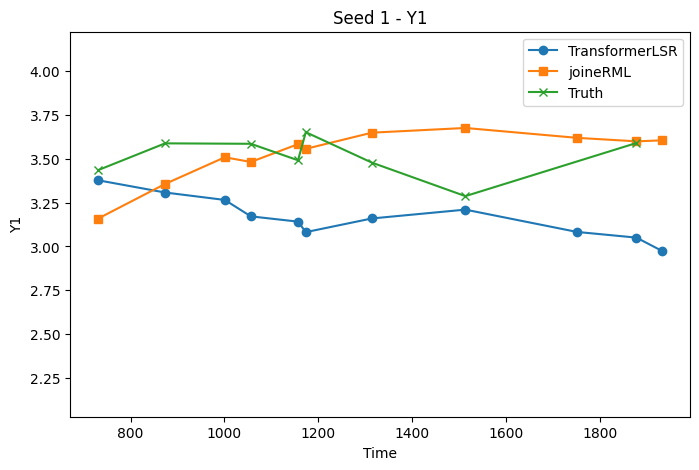

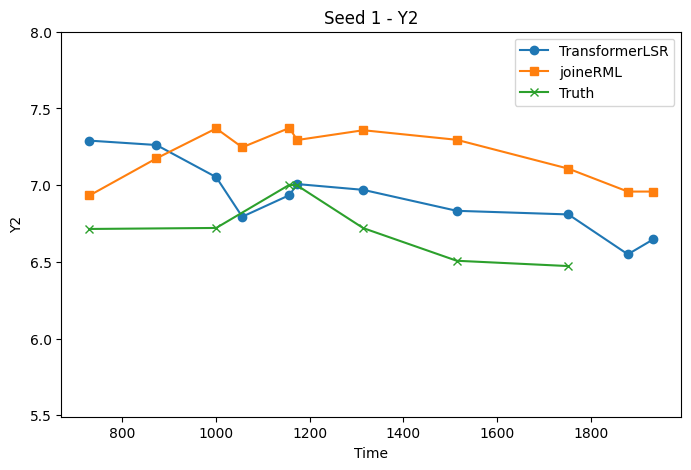

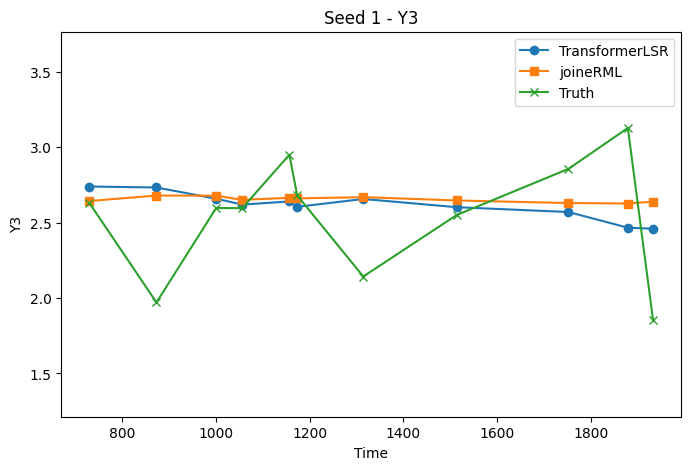

/tmp/ipykernel_58/1475092435.py:59: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.ylim(y_min - margin, y_max + margin)


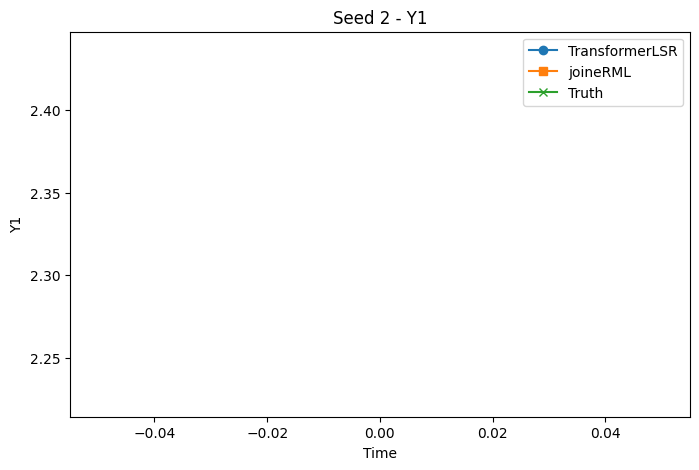

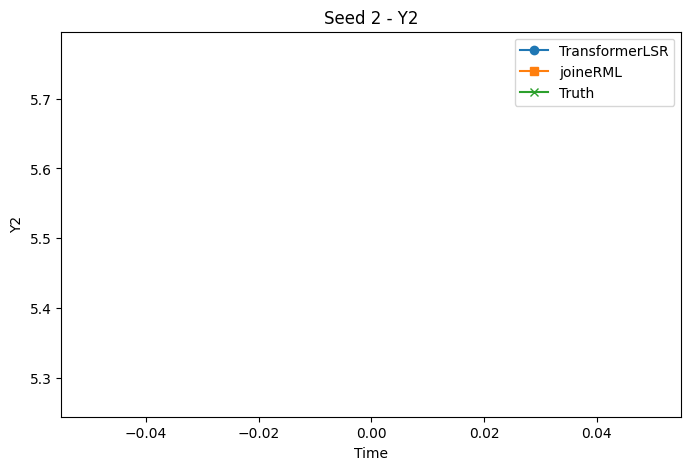

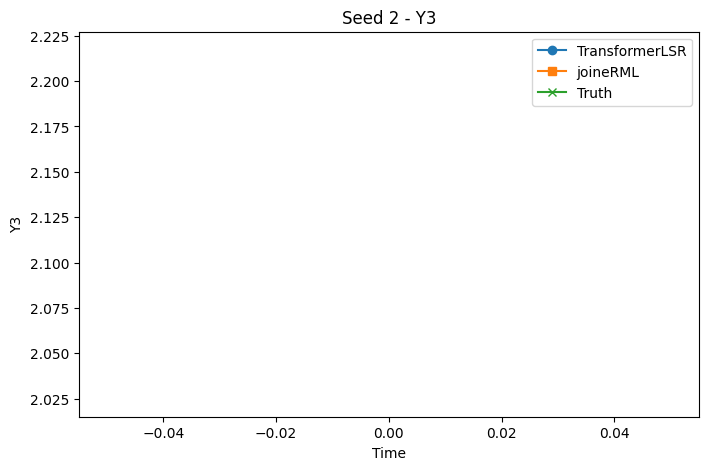

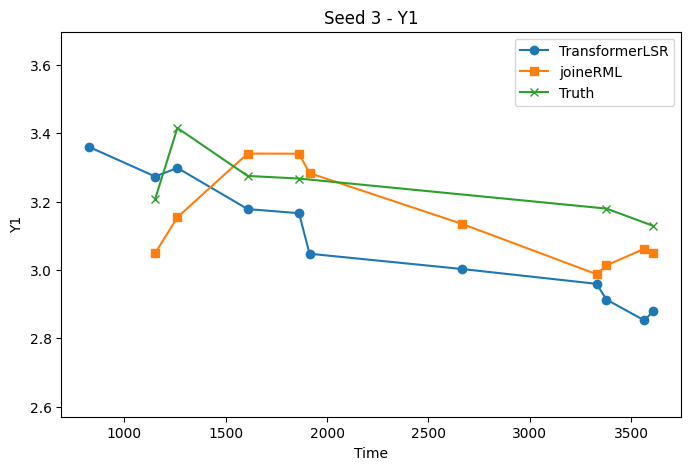

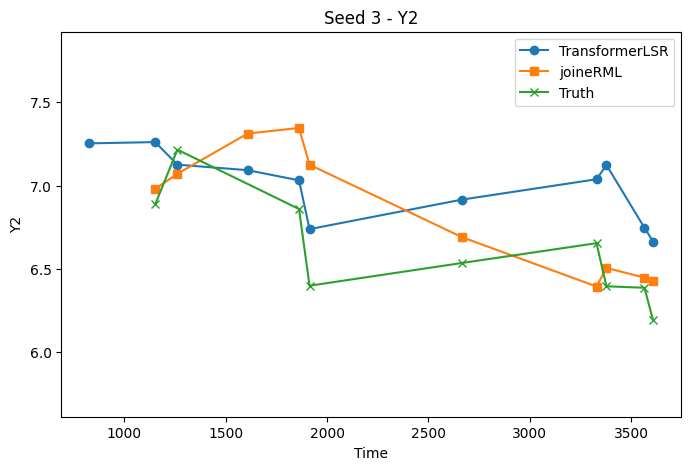

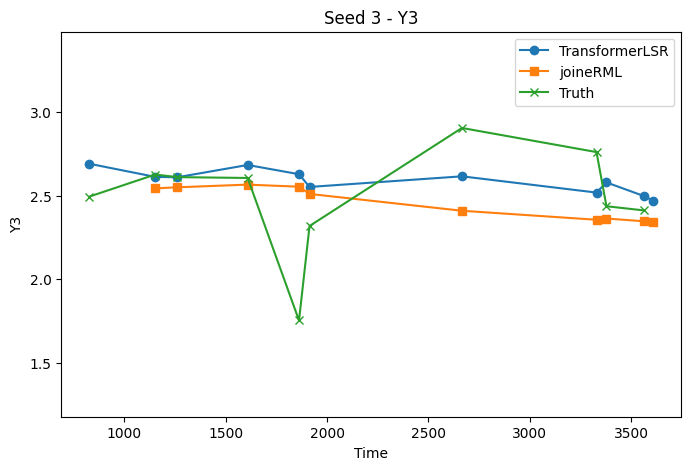

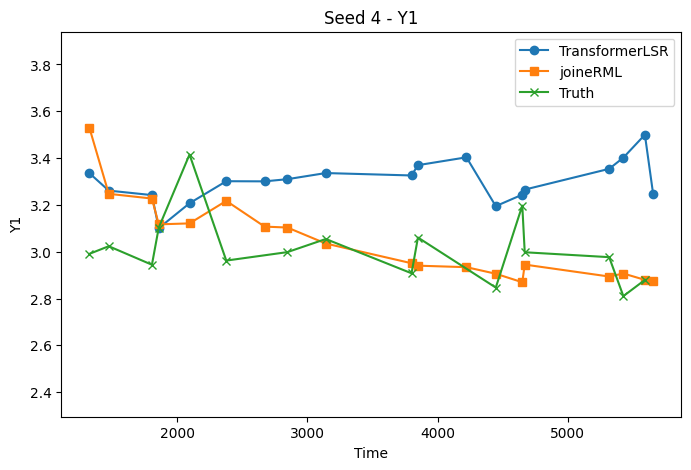

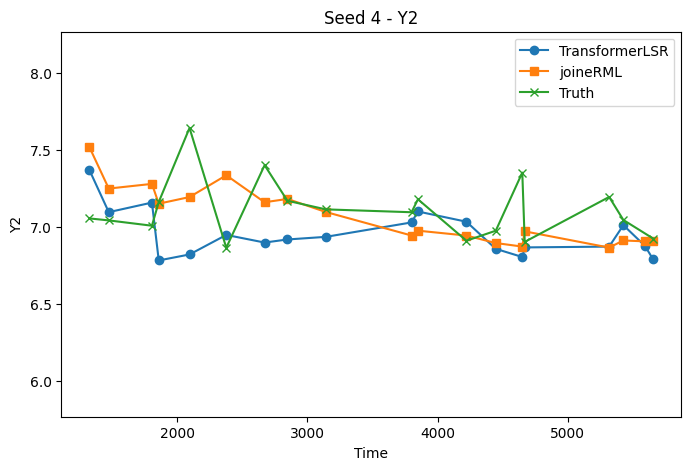

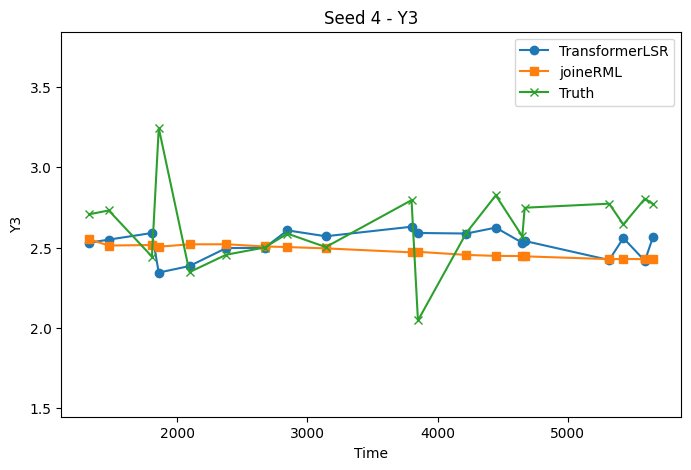

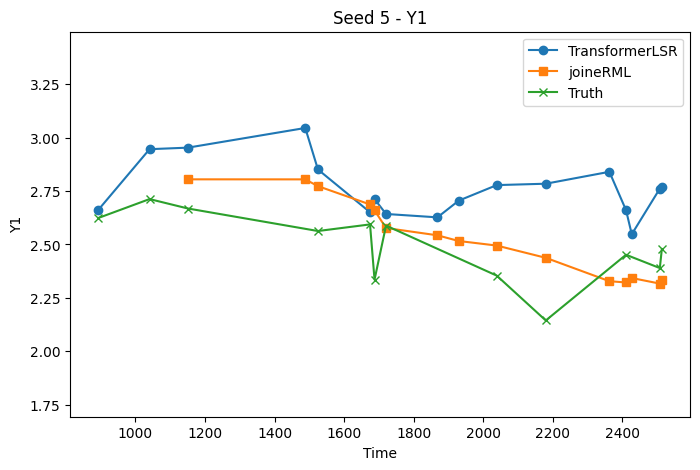

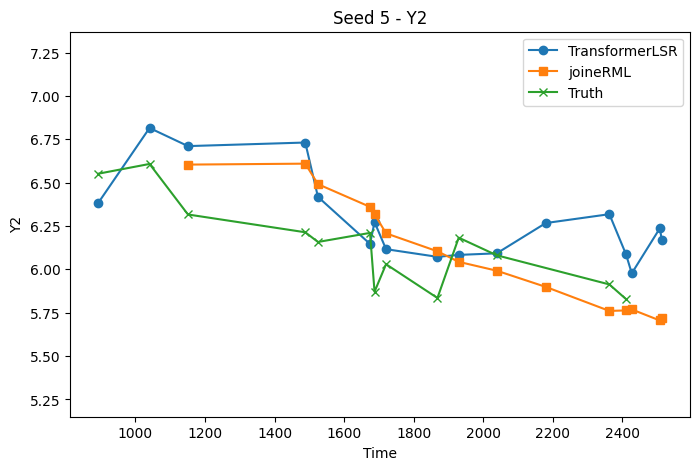

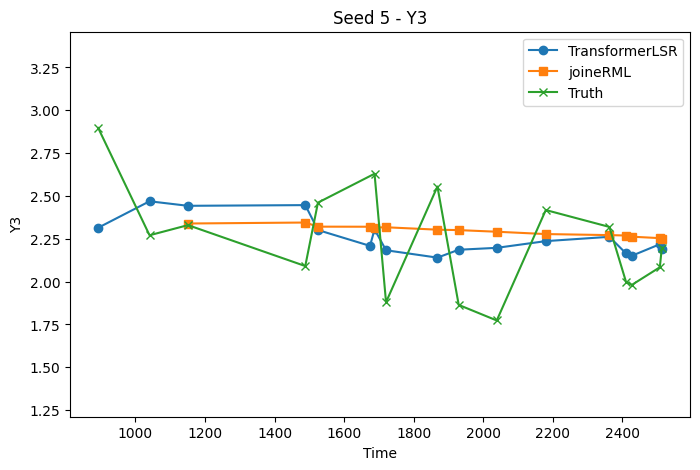

In [11]:
# Plotting longitudinal outcomes
eval_data_path = "/kaggle/input/datasets/jonasmschl/data-lsr-3/2_eval_data"

for i in range(5):

    seed = i + 1

    times = np.array(df_long.loc[i, "long_times"])
    nan_mask = np.array(df_long.loc[i, "long_nan_mask"])

    # joineRML results for the same seed
    joinerml = pd.read_csv(
        f"{eval_data_path}/long_results_seed_{seed}.csv"
    )

    # Same test patient as TransfomerLSR
    pid = 80

    for j in range(3):

        y = j + 1

        # LSR
        pred = np.array(df_long.loc[i, f"Y{y}_pred"])
        truth = np.array(df_long.loc[i, f"Y{y}_truth"])

        valid = ~nan_mask[:, j]

        # joineRML
        joinerml_y = (
            joinerml[
                (joinerml["id"] == pid) &
                (joinerml["outcome"] == f"Y{y}")
            ]
            .sort_values("obstime")
        )

        plt.figure(figsize=(8, 5))

        # LSR Prediction 
        plt.plot(times[1:], pred[1:], marker="o", label="TransformerLSR")

        # joineRML
        plt.plot(joinerml_y["obstime"].iloc[1:], joinerml_y["predicted"].iloc[1:], marker="s", label="joineRML")

        # Truth only where Y was observerd
        plt.plot(times[1:][valid[1:]], truth[1:][valid[1:]], marker="x", label="Truth")

        all_values = np.concatenate([
            pred[1:],
            joinerml_y["predicted"].to_numpy(),
            truth[1:][valid[1:]]
        ])
        
        y_min = np.min(all_values)
        y_max = np.max(all_values)
        margin = 0.5 * (y_max - y_min)
        
        plt.ylim(y_min - margin, y_max + margin)

        
        plt.ylim(y_min - margin, y_max + margin)
        plt.title(f"59% Censoring", fontsize=18)
        plt.xlabel("Time", fontsize=15)
        plt.ylabel(f"Y{y}", fontsize=15)
        plt.tick_params(axis="both", labelsize=15)
        plt.legend(fontsize=15)
        plt.show()

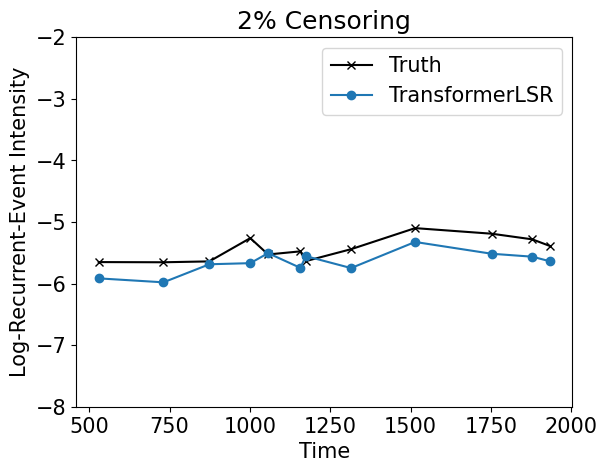

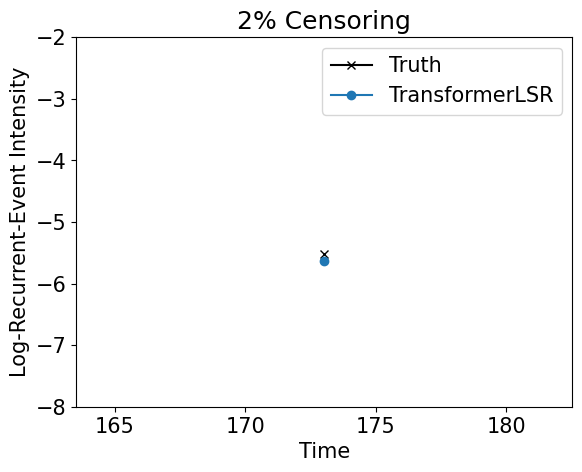

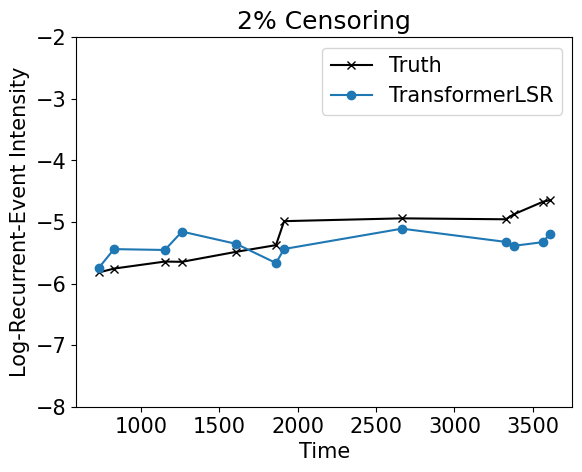

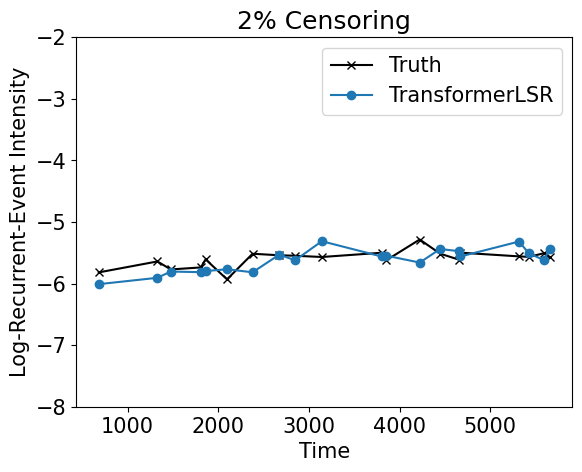

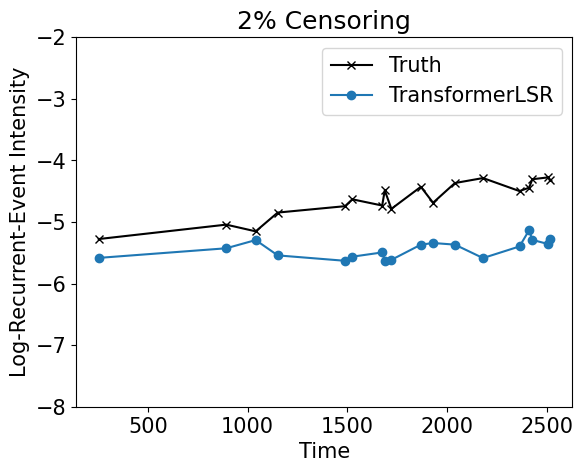

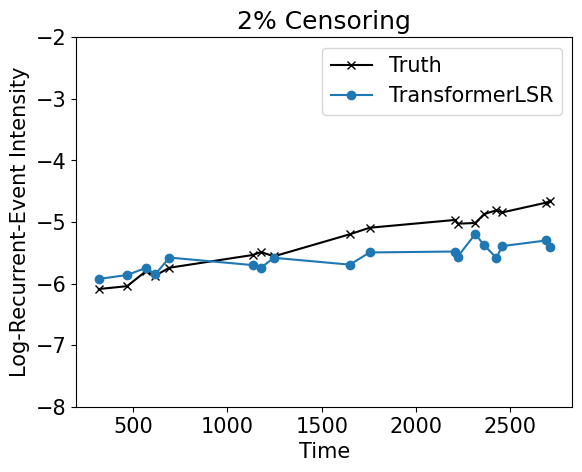

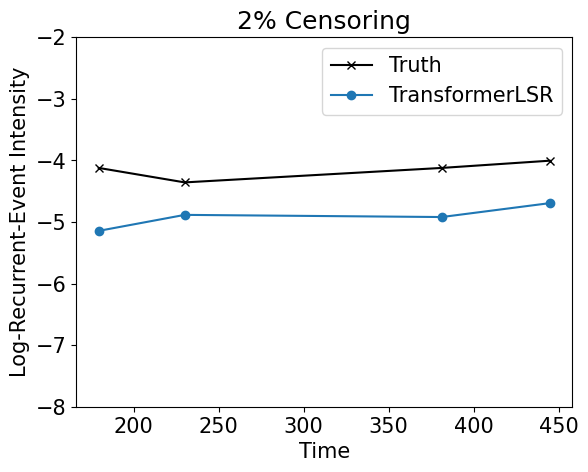

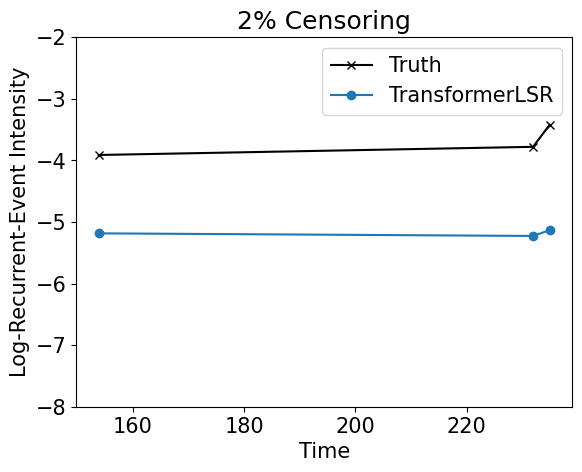

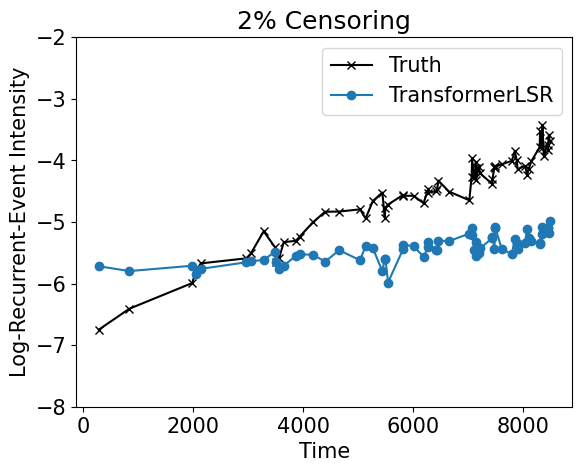

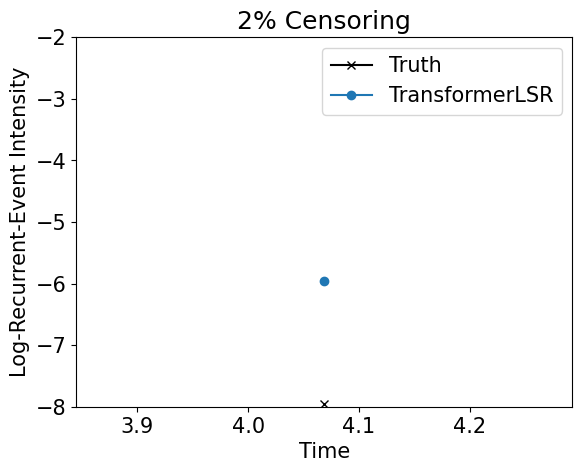

In [4]:
# Plotting recurrent event intensity
for i in range(10):
    plt.figure()
    plt.plot(df_inten["visit_times"][i], df_inten["visit_log_inten_truth"][i], marker="x", color="black", label="Truth")
    plt.plot(df_inten["visit_times"][i], df_inten["visit_log_inten_list"][i], marker="o", label="TransformerLSR")

    plt.title(f"2% Censoring", fontsize=18)
    plt.xlabel("Time", fontsize=15)
    plt.ylabel("Log-Recurrent-Event Intensity", fontsize=15)
    plt.tick_params(axis="both", labelsize=15)
    plt.legend(fontsize=15)
    plt.ylim(-8, -2)
    plt.show()

Seed 1: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


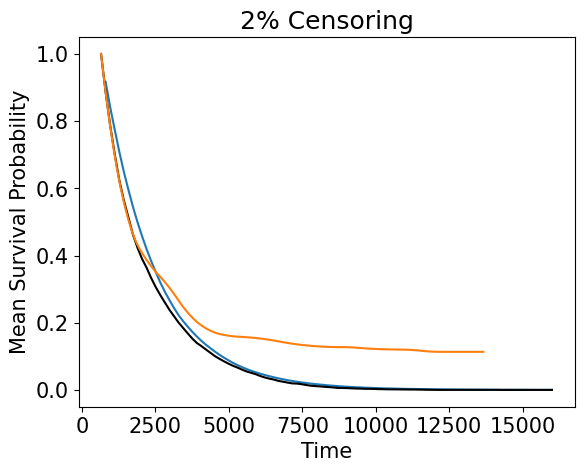

Seed 2: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


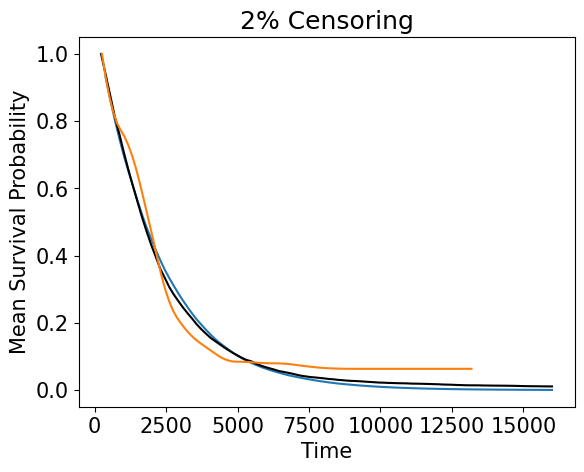

Seed 3: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


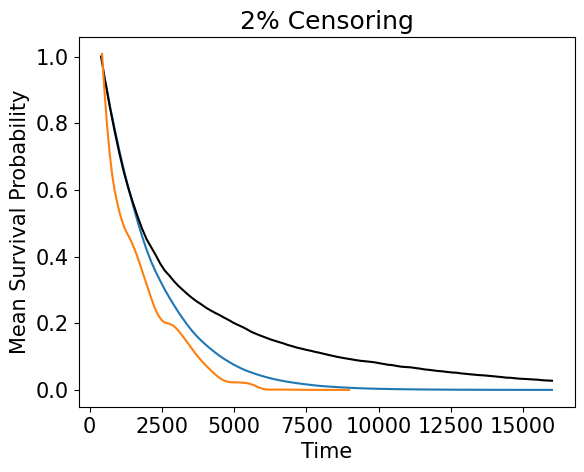

Seed 4: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


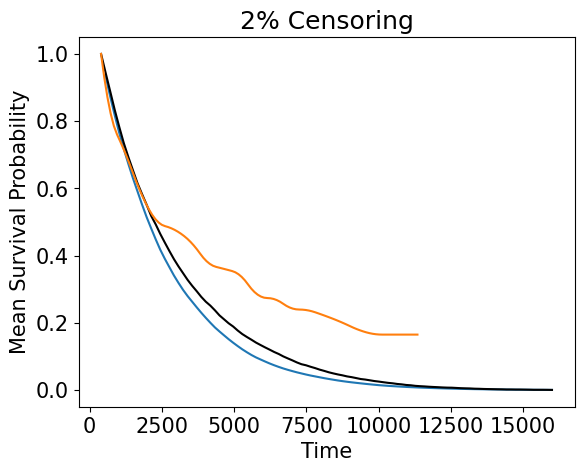

Seed 5: dict_keys(['LT', 'plot_times', 'eligible_test_ids', 'test_ids', 'n_paths', 'horizon', 'oracle_surv_by_patient', 'mean_oracle_surv', 'start_rows', 'mc_seed'])


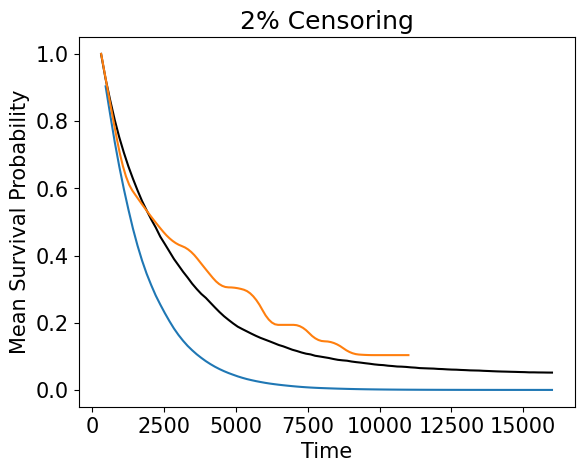

In [4]:
# Plotting Mean survival curve
for i in range(5):

    seed = i + 1

    # LSR
    pred_times = np.array(df_mean_surv.loc[i,"pred_times_plot"])
    mean_surv = np.array(df_mean_surv.loc[i,"mean_surv_plot"])

    valid_idx = pred_times >= df["LT"][i]

    # GT
    with open(f"results/predict_survival_seed_{seed}.pkl", "rb") as f:
        result_surv = pickle.load(f)
    print(f"Seed {seed}:", result_surv.keys())

    # joineRML
    joinerml = pd.read_csv(
        f"{eval_data_path}/mean_surv_smooth_joinerml_seed_{seed}.csv"
    )
    
    plt.figure()
    # LSR
    plt.plot(pred_times[valid_idx], mean_surv[valid_idx], label="TransformerLSR")
    # GT
    plt.plot(result_surv["plot_times"], result_surv["mean_oracle_surv"], label="Ground Truth", color="black")
    # joineRML
    #plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 2], label="joineRML")
    plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 3], label="joineRML (Smoothed)")
    

    plt.title(f"2% Censoring", fontsize=18)
    plt.xlabel("Time", fontsize=15)
    plt.ylabel("Mean Survival Probability", fontsize=15)
    plt.tick_params(axis="both", labelsize=15)
    #plt.legend(fontsize=15)
    plt.show()

In [ ]:
# Plotting Mean survival curve
for i in range(5):

    seed = i + 1

    # LSR
    pred_times = np.array(df_mean_surv.loc[i,"pred_times_plot"])
    mean_surv = np.array(df_mean_surv.loc[i,"mean_surv_plot"])

    valid_idx = pred_times >= df["LT"][i]

    # GT
    with open(f"results/predict_survival_seed_{seed}.pkl", "rb") as f:
        result_surv = pickle.load(f)
    print(f"Seed {seed}:", result_surv.keys())

    # joineRML
    joinerml = pd.read_csv(
        f"{eval_data_path}/mean_surv_smooth_joinerml_seed_{seed}.csv"
    )
    
    plt.figure()
    # LSR
    plt.plot(pred_times[valid_idx], mean_surv[valid_idx], label="TransformerLSR")
    # GT
    plt.plot(result_surv["plot_times"], result_surv["mean_oracle_surv"], label="Ground Truth")
    # joineRML
    plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 2], label="joineRML")
    #plt.plot(joinerml.iloc[:, 1], joinerml.iloc[:, 3], label="joineRML (Smoothed)")
    

    plt.xlabel("Time")
    plt.ylabel("Mean Survival Probability")
    plt.legend()
    plt.show()